# Matches between people

The real match network from the Columbia Speed Dating data, read from Neo4j.
Needs Neo4j running with the data loaded: `docker compose up -d`, then `python prepare_data.py`.

In [1]:
%matplotlib inline
# Re-read project .py files (plot_style, speed_dating, ...) when they change, without a kernel restart
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.lines import Line2D

from plot_style import (
    BLUE, GENDER_COLORS, INK_2, MATCH_COLOR, MATCH_LINE, MUTED, NO_MATCH_COLOR, SURFACE,
    gender_legend, match_graph, network_layout, no_axes,
)
from speed_dating import load_pairs, load_people

people, pairs = load_people(), load_pairs()
print(f"{len(people)} people, {len(pairs)} dates, {pairs['match'].sum()} matches")

551 people, 4184 dates, 690 matches


## Match network

Each line is a match (both people said yes). Each cluster is one speed-dating event:
people only dated others at the same event.

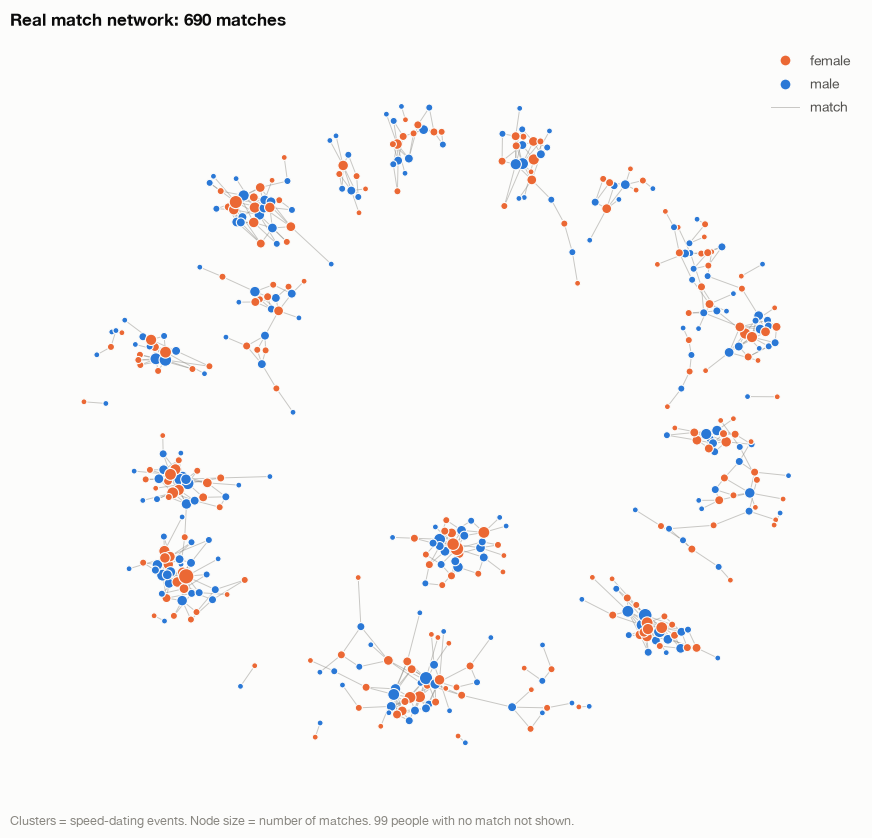

In [2]:
graph = match_graph(people, pairs)
pos = network_layout(graph)
nodes = list(graph.nodes)

fig, ax = plt.subplots(figsize=(11, 10))
nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=MATCH_LINE["color"],
                       width=MATCH_LINE["linewidth"], alpha=MATCH_LINE["alpha"])
nx.draw_networkx_nodes(graph, pos, nodelist=nodes, ax=ax,
                       node_color=[GENDER_COLORS[graph.nodes[n]["gender"]] for n in nodes],
                       node_size=[10 + 8 * graph.degree(n) for n in nodes],
                       edgecolors=SURFACE, linewidths=0.8)
no_axes(ax)
n_alone = len(people) - graph.number_of_nodes()
ax.set_title(f"Real match network: {graph.number_of_edges()} matches")
ax.text(0, -0.02, f"Clusters = speed-dating events. Node size = number of matches. "
        f"{n_alone} people with no match not shown.", transform=ax.transAxes, color=MUTED, fontsize=9)
gender_legend(ax)

## Every date: match or not

All 4,184 dates, one panel per event. People sit on a circle, women on the left half and men
on the right, so every line across the circle is one date. Green = match (both said yes),
red = no match. Matches are drawn on top so they stay visible among the red lines.

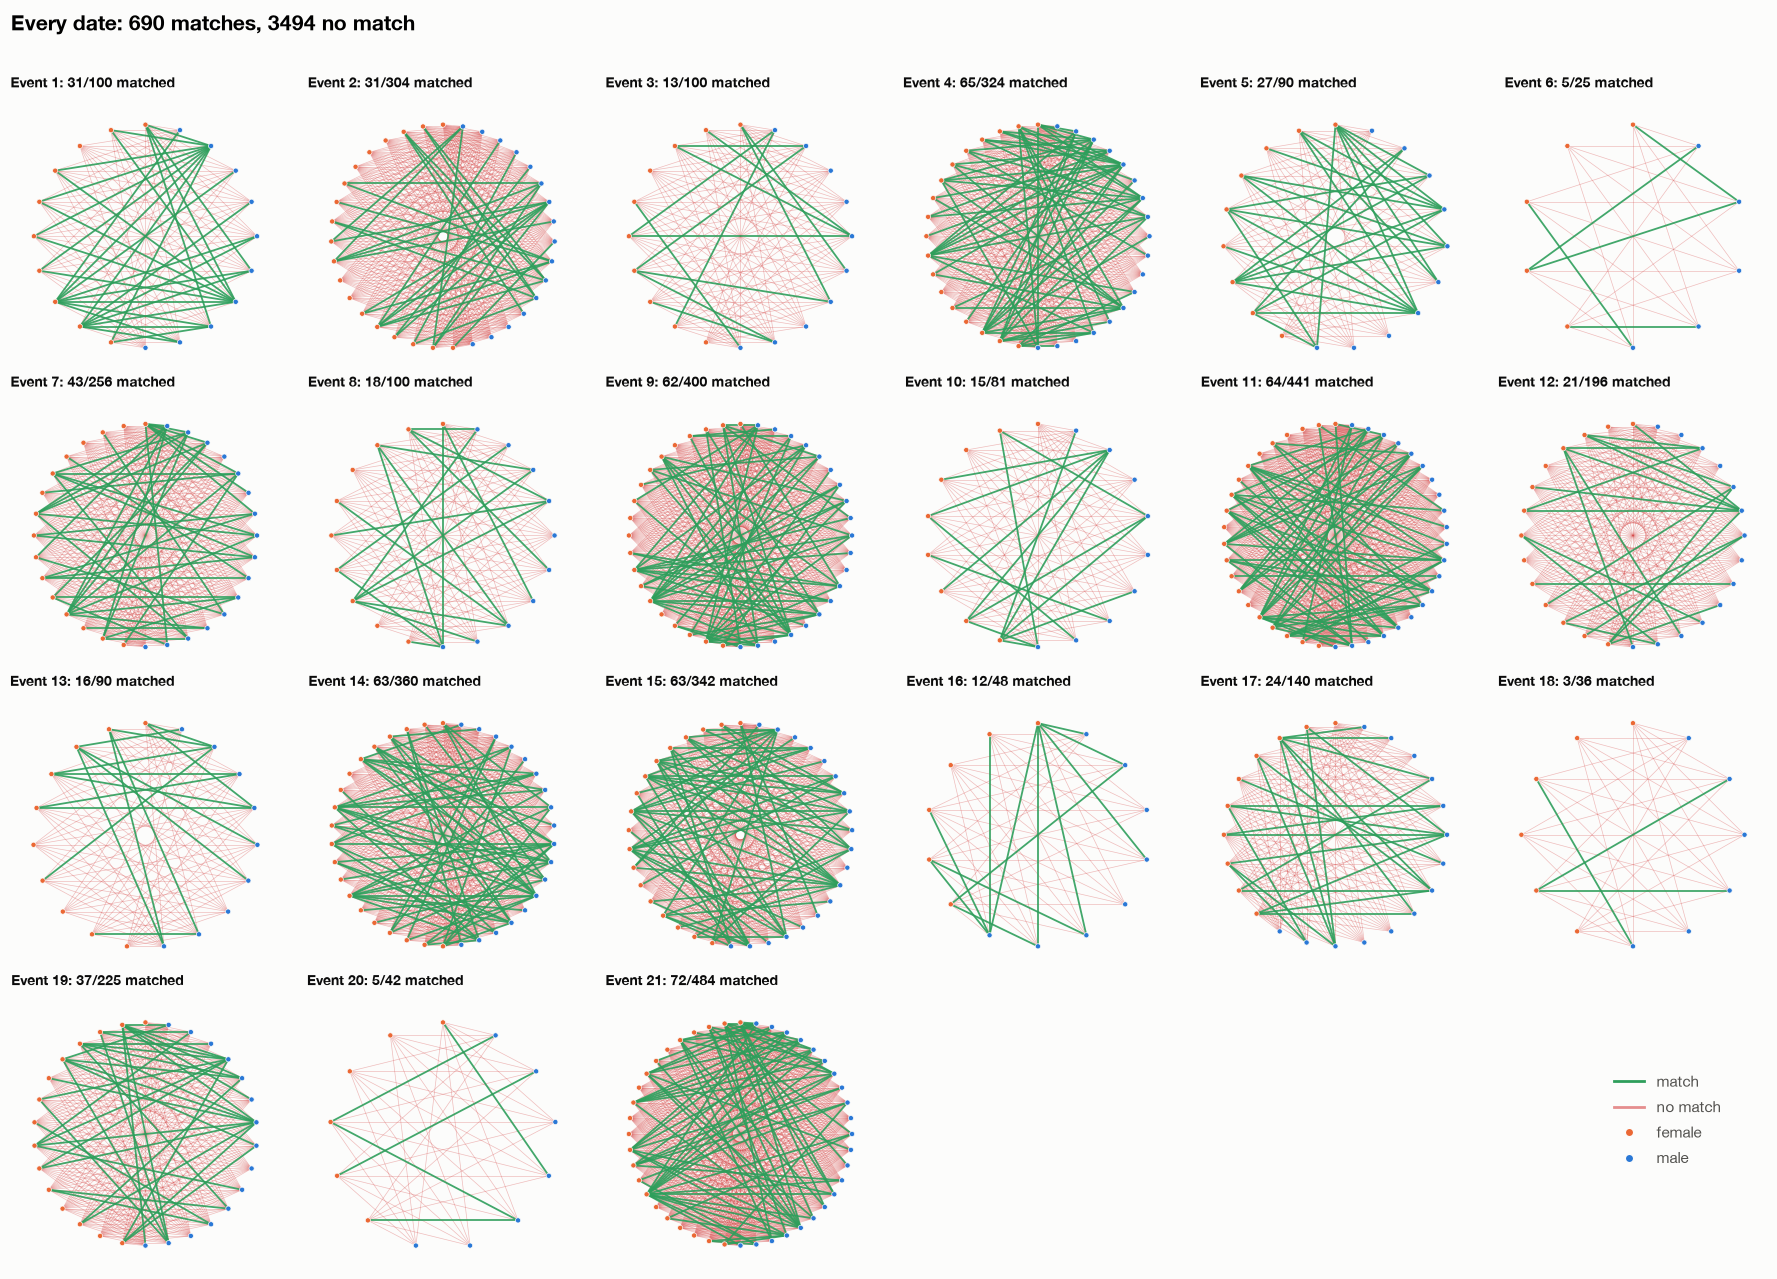

In [3]:
wave_of = people.set_index("id")["wave"]
pairs["wave"] = pairs["person_a"].map(wave_of)  # both people on a date are from the same event
waves = sorted(people["wave"].unique())

fig, axes = plt.subplots(4, 6, figsize=(18, 13))
for ax, wave in zip(axes.flat, waves):
    here = people[people["wave"] == wave].sort_values(["gender", "id"])  # female first: left half
    dates = pairs[pairs["wave"] == wave]
    graph = nx.Graph()
    graph.add_nodes_from(here["id"])
    graph.add_edges_from(dates[["person_a", "person_b"]].itertuples(index=False))
    # Start at the top and go anticlockwise, so women fill the left half and men the right
    angles = np.pi / 2 + 2 * np.pi * np.arange(len(here)) / len(here)
    pos = {pid: (np.cos(a), np.sin(a)) for pid, a in zip(here["id"], angles)}

    for outcome, color, width, alpha in ((0, NO_MATCH_COLOR, 0.5, 0.35), (1, MATCH_COLOR, 1.3, 0.9)):
        edges = dates.loc[dates["match"] == outcome, ["person_a", "person_b"]].itertuples(index=False)
        nx.draw_networkx_edges(graph, pos, edgelist=list(edges), ax=ax, edge_color=color, width=width, alpha=alpha)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=14, edgecolors=SURFACE, linewidths=0.5,
                           node_color=[GENDER_COLORS[g] for g in here["gender"]])
    no_axes(ax)
    ax.set_aspect("equal")
    ax.set_title(f"Event {wave}: {dates['match'].sum()}/{len(dates)} matched", fontsize=10)
for ax in axes.flat[len(waves):]:
    ax.set_visible(False)

fig.legend(handles=[Line2D([], [], color=MATCH_COLOR, linewidth=2, label="match"),
                    Line2D([], [], color=NO_MATCH_COLOR, linewidth=2, alpha=0.6, label="no match"),
                    Line2D([], [], marker="o", linestyle="", markerfacecolor=GENDER_COLORS["female"],
                           markeredgecolor=SURFACE, label="female"),
                    Line2D([], [], marker="o", linestyle="", markerfacecolor=GENDER_COLORS["male"],
                           markeredgecolor=SURFACE, label="male")],
           loc="lower right", bbox_to_anchor=(0.97, 0.08), fontsize=11)
fig.suptitle(f"Every date: {pairs['match'].sum()} matches, {(pairs['match'] == 0).sum()} no match",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))